# 05 — Analyse causale : le tutorat fait-il baisser le décrochage ?

**Projet Horizon : décrochage et tutorat** — tâches CA-01 (DAG, entrée en tutorat, photo de la semaine 8), CA-02 (score de propension, support commun), CA-03 (poids, équilibre), CA-04 (effet) et CA-05 (sensibilité).

Ce notebook lit `data/processed/` (il ne relance pas le pipeline) ; les calculs sont dans `src/causal.py`.
Décisions appliquées : D-53 (photo de la semaine 8), D-54 (règles de la photo), D-55 (DAG et variables du score), D-56 (score, poids, équilibre), D-57 (mesures de l'effet), D-58 et D-62 (sensibilité), D-59 et D-61 (garde-fous, réglages figés).

> **Conception d'abord (D-59).** Les sections 1 à 8 (conception) ne comparent **jamais** le décrochage entre tutorés et non tutorés. Elles ont été relues (R02) et figées avant le calcul de l'effet. Les sections 9 à 11 (effet et sensibilité) lisent les résultats produits par `python run_all.py` dans `data/processed/resultats/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
from matplotlib.ticker import PercentFormatter

# Le notebook est dans notebooks/ : on remonte jusqu'à la racine du dépôt (dossier qui
# contient src/config.py) pour pouvoir importer src/, quel que soit le dossier de lancement.
racine = Path.cwd()
while not (racine / "src" / "config.py").exists():
    racine = racine.parent
sys.path.insert(0, str(racine))

from src import causal, config, eda

pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 60)
config.DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)
L = config.SEMAINE_LANDMARK


def enregistrer(figure, nom):
    """Enregistre une figure en PNG dans docs/figures/ et l'affiche."""
    figure.tight_layout()
    figure.savefig(config.DOSSIER_FIGURES / nom, dpi=120)
    plt.show()


def nombre(x, decimales=1):
    """Nombre au format français, ex. 68,4."""
    return f"{x:.{decimales}f}".replace(".", ",")


def signe(x, decimales=2):
    """Nombre signé au format français, ex. +0,59 ou −0,42."""
    texte = nombre(abs(x), decimales)
    return f"+{texte}" if x >= 0 else f"−{texte}"


def entier(n):
    """Entier avec séparateur des milliers, ex. 4 316."""
    return f"{int(n):,}".replace(",", " ")


base, periode = eda.lire_bases()
print(f"{entier(len(base))} étudiants ; {entier(len(periode))} lignes étudiant-semaine d'activité.")

5 000 étudiants ; 121 938 lignes étudiant-semaine d'activité.


## 1. Ce qu'on cherche

**La question** : le tutorat *fait-il baisser* le décrochage ? Il ne suffit pas de comparer les tutorés aux autres, pour deux raisons.

1. **Le biais de sélection** : on oriente vers le tutorat les étudiants qui vont déjà mal (notes faibles, absences). Les tutorés partent donc avec un risque plus élevé ; une comparaison brute ferait paraître le tutorat inefficace, voire nuisible.
2. **Le biais du temps immortel** : on ne peut être tutoré que si l'on est encore inscrit. Un étudiant tutoré en semaine 10 a forcément « survécu » 9 semaines ; si l'on compte ces semaines au crédit du tutorat, on le flatte à tort.

**La démarche « conception d'abord » (D-59)** : on fixe et on vérifie toute la méthode (photo, score de propension, poids, équilibre des deux équipes) **avant** de regarder le moindre chiffre de décrochage par équipe. Ainsi, la méthode ne peut pas être ajustée pour obtenir le résultat souhaité.

## 2. Le moment d'entrée en tutorat

La répartition des semaines de début a été décrite dans l'analyse exploratoire (notebook 02) :

![Semaine de début du tutorat](../docs/figures/02_debut_tutorat.png)

In [2]:
entree = causal.entree_en_tutorat(base, L)
tableau_entree = entree["tableau"].rename(columns={"semaine": "Semaine de début", "effectif": "Tutorats commencés",
                                                  "pct_cumule": "% cumulé"})
display(tableau_entree.round(1).set_index("Semaine de début").T)
print(f"{entier(entree['nb_debuts'])} tutorats commencent pendant le suivi, entre les semaines {entree['premiere']} "
      f"et {entree['derniere']} ; {entier(entree['nb_au_plus_tard'])} d'entre eux ({nombre(entree['part_au_plus_tard'])} %) "
      f"commencent au plus tard en semaine {L}. Le tutorat se décide donc surtout pendant les deux premiers mois.")

Semaine de début,3,4,5,6,7,8,9,10,11,12,18,19,21,24,25
Tutorats commencés,180.0,143.0,130.0,150.0,134.0,114.0,122.0,97.0,91.0,78.0,1.0,1.0,1.0,1.0,2.0
% cumulé,14.5,25.9,36.4,48.4,59.2,68.4,78.2,85.9,93.3,99.5,99.6,99.7,99.8,99.8,100.0


1 245 tutorats commencent pendant le suivi, entre les semaines 3 et 25 ; 851 d'entre eux (68,4 %) commencent au plus tard en semaine 8. Le tutorat se décide donc surtout pendant les deux premiers mois.


In [3]:
motifs = entree["motifs"]
tableau_motifs = pd.DataFrame({"Tutorats": motifs, "%": (100 * motifs / motifs.sum()).round(1)})
tableau_motifs.index.name = "Motif d'orientation"
display(tableau_motifs)
demande = motifs.get("demande personnelle", 0)
print(f"Sur {entier(motifs.sum())} tutorats, {nombre(100 * (motifs.sum() - demande) / motifs.sum(), 0)} % démarrent sur "
      f"une difficulté repérée (notes faibles, absences, signalement d'un enseignant) ; seuls {entier(demande)} "
      "sont demandés par l'étudiant lui-même.")

,Tutorats,%
Motif d'orientation,,
notes faibles,486,38.7
absences répétées,326,26.0
signalement enseignant,240,19.1
demande personnelle,203,16.2


Sur 1 255 tutorats, 84 % démarrent sur une difficulté repérée (notes faibles, absences, signalement d'un enseignant) ; seuls 203 sont demandés par l'étudiant lui-même.


### Ce qui précède l'entrée en tutorat

Pour chaque semaine de début k (3 à 12), on compare les étudiants qui **commencent** le tutorat en semaine k aux autres étudiants **encore suivis et pas encore tutorés** (« éligibles »), sur leur activité moyenne des **2 semaines précédentes** (k − 2 et k − 1). L'écart standardisé (SMD) exprime la différence en nombre d'écarts-types : au-delà de 0,1 en valeur absolue, l'écart n'est plus négligeable ; au-delà de 0,5, il est fort.

In [4]:
precede = causal.ce_qui_precede_entree(base, periode)
noms_activite = {"nb_connexions_lms": "connexions", "devoirs_rendus": "devoirs", "note_moyenne": "notes",
                 "absences": "absences"}
affichage = precede.rename(columns={"k": "Semaine de début k", "commencent": "Commencent", "eligibles": "Éligibles"})
affichage = affichage.rename(columns={f"smd_{v}": f"SMD {nom}" for v, nom in noms_activite.items()})
display(affichage.set_index("Semaine de début k").round(2))


def etendue(colonne):
    """Plus petit et plus grand écart d'une colonne, au format « de a à b »."""
    valeurs = precede[colonne]
    return f"de {signe(valeurs.min())} à {signe(valeurs.max())}"


print(f"Dans les 2 semaines qui précèdent leur entrée en tutorat, les futurs tutorés ont des notes plus basses "
      f"(écart standardisé {etendue('smd_note_moyenne')} selon la semaine de début), plus d'absences "
      f"({etendue('smd_absences')}), moins de connexions ({etendue('smd_nb_connexions_lms')}) et moins de devoirs "
      f"rendus ({etendue('smd_devoirs_rendus')}) que les étudiants encore suivis et pas encore tutorés.")
print("Autrement dit, le tutorat arrive juste après une mauvaise passe : c'est le biais de sélection. Pour comparer "
      "équitablement, il faut tenir compte de cette activité récente, pas seulement du profil à la rentrée.")

,Commencent,Éligibles,SMD connexions,SMD devoirs,SMD notes,SMD absences
Semaine de début k,,,,,,
3,180,4879,-0.42,-0.36,-0.93,0.59
4,143,4617,-0.37,-0.28,-0.54,0.47
5,130,4384,-0.46,-0.38,-0.50,0.46
6,150,4158,-0.48,-0.41,-0.56,0.60
7,131,3913,-0.36,-0.34,-0.61,0.52
8,113,3716,-0.52,-0.32,-0.74,0.57
9,120,3543,-0.57,-0.30,-0.74,0.64
10,95,3375,-0.18,-0.15,-0.44,0.43
11,91,3254,-0.32,-0.32,-0.60,0.45


Dans les 2 semaines qui précèdent leur entrée en tutorat, les futurs tutorés ont des notes plus basses (écart standardisé de −0,93 à −0,44 selon la semaine de début), plus d'absences (de +0,43 à +0,64), moins de connexions (de −0,57 à −0,18) et moins de devoirs rendus (de −0,43 à −0,15) que les étudiants encore suivis et pas encore tutorés.
Autrement dit, le tutorat arrive juste après une mauvaise passe : c'est le biais de sélection. Pour comparer équitablement, il faut tenir compte de cette activité récente, pas seulement du profil à la rentrée.


## 3. Le graphe causal (DAG)

Le DAG résume ce que l'on suppose des liens entre les variables (D-55). Chaque flèche se lit « influence ».

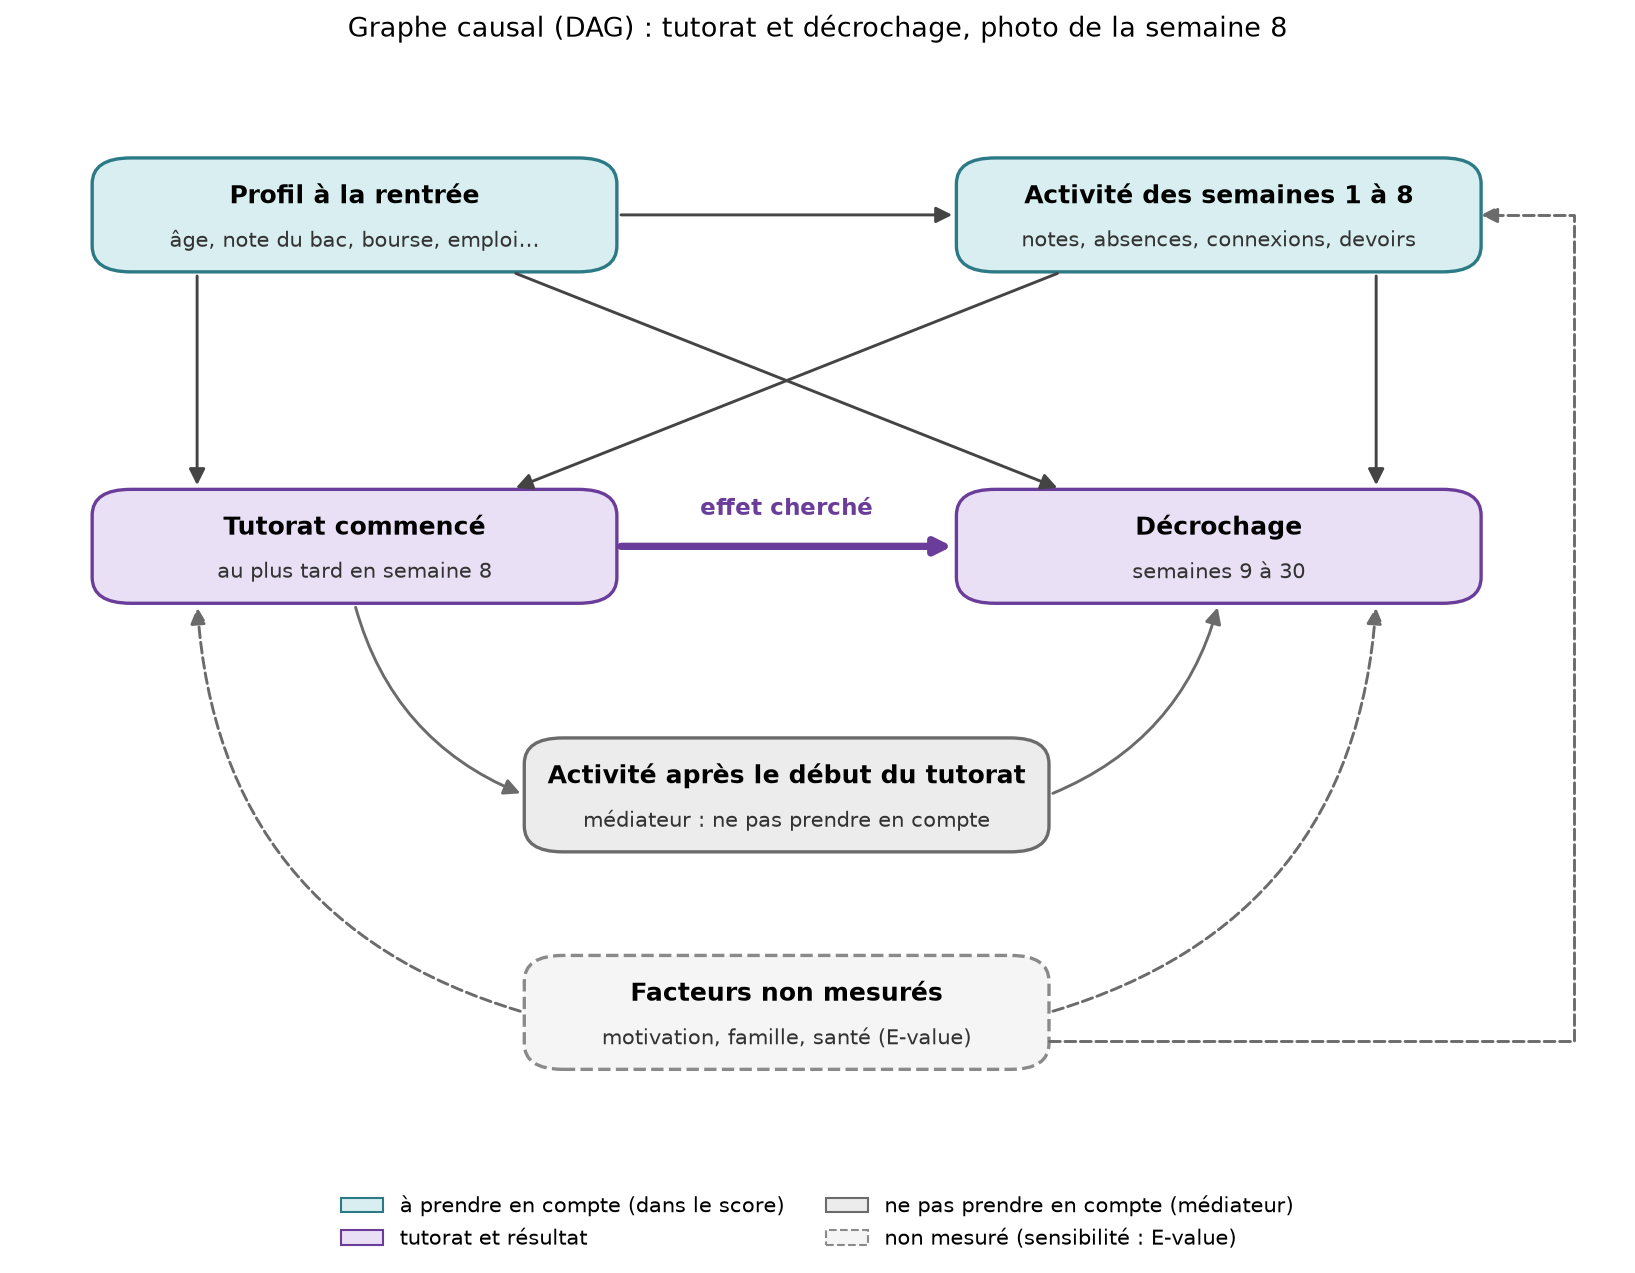

In [5]:
chemin_dag = config.DOSSIER_FIGURES / "05_dag.png"
causal.dessiner_dag(chemin_dag)
display(Image(filename=str(chemin_dag), width=800))

**Les trois « portes dérobées »** : trois chemins relient le tutorat au décrochage sans passer par l'effet cherché. Ils créent une association même si le tutorat n'avait aucun effet.

1. **Le profil à la rentrée** (âge, note du bac, bourse, emploi…) influence à la fois l'orientation vers le tutorat et le décrochage.
2. **L'activité des semaines 1 à 8** (notes, absences, connexions, devoirs) : une mauvaise passe déclenche le tutorat (voir le tableau ci-dessus) et annonce aussi le décrochage.
3. **Les facteurs non mesurés** (motivation, famille, santé) : ils peuvent influencer l'orientation vers le tutorat, l'activité des premières semaines et le décrochage. On ne peut pas les fermer avec les données ; leur poids possible sera évalué par l'E-value (CA-05).

**Ce qu'on prend en compte** (dans le score de propension) : le profil à la rentrée, codé comme dans le modèle de Cox (D-49, D-50), et l'activité moyenne des semaines 1 à 8 — cela ferme les portes 1 et 2.

**Ce qu'on ne prend surtout pas en compte** :
- l'**activité après le début du tutorat** : c'est un médiateur, le chemin par lequel le tutorat peut agir (il améliore les notes, qui retiennent l'étudiant). L'ajuster effacerait une partie de l'effet que l'on cherche ;
- `nb_seances` et `type_tuteur` : ils n'existent qu'une fois le tutorat commencé et dépendent de son déroulement (et du décrochage : un étudiant qui part suit moins de séances) ;
- `motif_orientation` : il n'existe que pour les tutorés ; il ne peut pas servir à comparer les deux équipes.

**Limite écrite d'avance (D-55)** : pour les tutorats commencés tôt (semaines 3 à 7), une partie de la fenêtre des semaines 1 à 8 est postérieure à leur début. Si le tutorat a déjà amélioré l'activité de ces semaines, une partie de son effet est absorbée par l'ajustement : l'estimation sera plutôt prudente. La fenêtre des semaines 1 à 2 (avant tout tutorat) sera testée en sensibilité (CA-05).

In [6]:
estime = causal.ce_qu_on_estime(base, periode, causal.population_photo(base, L), L)
print(f"Les boîtes « Activité des semaines 1 à {L} » et « Activité après le début du tutorat » se recouvrent en partie : "
      f"chez les tutorés de la photo, en moyenne {nombre(estime['recouvrement_moyen'])} des {L} semaines de la fenêtre vont "
      f"de la semaine du début à la semaine {L} (début compris). Ce recouvrement est écrit ici plutôt que dessiné : une "
      "flèche donnerait l'impression d'une boucle (D-61).")

Les boîtes « Activité des semaines 1 à 8 » et « Activité après le début du tutorat » se recouvrent en partie : chez les tutorés de la photo, en moyenne 3,6 des 8 semaines de la fenêtre vont de la semaine du début à la semaine 8 (début compris). Ce recouvrement est écrit ici plutôt que dessiné : une flèche donnerait l'impression d'une boucle (D-61).


## 4. Le choix de la photo (semaine 8)

Contre le temps immortel, on prend une **photo** à la fin d'une semaine L (D-53, D-54) : on ne garde que les étudiants encore suivis et sans décrochage à ce moment ; ceux qui ont déjà commencé le tutorat forment l'équipe « tutorés », les autres l'équipe « non tutorés » ; le suivi reprend la semaine suivante pour tout le monde. Un tutorat commencé après la photo compte comme « pas tutoré » : on ne regarde pas l'avenir pour composer les équipes.

Le tableau compare plusieurs semaines possibles (les sorties avant la photo sont comptées **toutes équipes confondues**).

In [7]:
photos = causal.tableau_des_photos(base, config.PHOTOS_COMPAREES)
colonnes_photos = {
    "photo": "Photo (semaine L)", "sur_la_photo": "Sur la photo", "sortis_avant": "Sortis avant",
    "dont_decrochages": "dont décrochages", "tutores": "Tutorés", "pct_tutores": "% tutorés",
    "non_tutores": "Non tutorés", "futurs_tutores": "Futurs tutorés", "pct_futurs_tutores": "% futurs tutorés",
    "pct_debuts_couverts": "% débuts couverts", "tutores_partis_avant": "Tutorés partis avant",
    "semaines_apres_photo": "Semaines suivies après", "inconnus_retires": "Début inconnu retirés",
}
display(photos.rename(columns=colonnes_photos).set_index("Photo (semaine L)").round(1).T)
ligne = photos.set_index("photo")
p6, p8, p10 = ligne.loc[6], ligne.loc[8], ligne.loc[10]
print(f"Une photo trop tôt laisse beaucoup de futurs tutorés chez les « non tutorés » : {nombre(p6['pct_futurs_tutores'])} % "
      f"en semaine 6, contre {nombre(p8['pct_futurs_tutores'])} % en semaine 8 ; elle ne couvre que "
      f"{nombre(p6['pct_debuts_couverts'])} % des débuts, contre {nombre(p8['pct_debuts_couverts'])} %. Une photo trop tard "
      f"perd des tutorés partis avant elle ({entier(p10['tutores_partis_avant'])} en semaine 10, contre "
      f"{entier(p8['tutores_partis_avant'])} en semaine 8) et raccourcit le suivi ({entier(p10['semaines_apres_photo'])} semaines "
      f"au lieu de {entier(p8['semaines_apres_photo'])}).")

Photo (semaine L),4,6,8,10,12
Sur la photo,4694.0,4473.0,4316.0,4225.0,4156.0
Sortis avant,301.0,522.0,680.0,771.0,840.0
dont décrochages,285.0,501.0,656.0,733.0,794.0
Tutorés,310.0,560.0,773.0,971.0,1116.0
% tutorés,6.6,12.5,17.9,23.0,26.9
Non tutorés,4384.0,3913.0,3543.0,3254.0,3040.0
Futurs tutorés,921.0,635.0,389.0,174.0,6.0
% futurs tutorés,21.0,16.2,11.0,5.3,0.2
% débuts couverts,25.9,48.4,68.4,85.9,99.5
Tutorés partis avant,4.0,23.0,45.0,62.0,83.0


Une photo trop tôt laisse beaucoup de futurs tutorés chez les « non tutorés » : 16,2 % en semaine 6, contre 11,0 % en semaine 8 ; elle ne couvre que 48,4 % des débuts, contre 68,4 %. Une photo trop tard perd des tutorés partis avant elle (62 en semaine 10, contre 45 en semaine 8) et raccourcit le suivi (20 semaines au lieu de 22).


**Pourquoi la semaine 8 (D-53)** : c'est un compromis entre la part des tutorats pris en compte, la dilution par les futurs tutorés et la durée du suivi après la photo. La photo tombe juste après la vague de décrochages des semaines 4 à 7 et avant le pic des semaines 15-16 (notebook 03), et c'est l'exemple du cahier des charges. Les photos des semaines 6 et 10 seront présentées en sensibilité (CA-05), jamais à la place de l'analyse principale.

**Conséquence assumée (D-54)** : les futurs tutorés restent dans l'équipe « non tutorés », ce qui dilue un peu l'effet ; les déplacer chez les tutorés recréerait le temps immortel, les retirer reviendrait à choisir les équipes avec l'avenir.

In [8]:
population = causal.population_photo(base, L)
tutores_photo = int(population["tutore_photo"].sum())
non_tutores_photo = len(population) - tutores_photo
print(f"Photo retenue (fin de la semaine {L}) : {entier(len(population))} étudiants, dont {entier(tutores_photo)} tutorés "
      f"({nombre(100 * tutores_photo / len(population))} %) et {entier(non_tutores_photo)} non tutorés. "
      f"{entier(p8['inconnus_retires'])} étudiants à semaine de début inconnue sont retirés de l'analyse causale (D-54) ; "
      f"ils restent dans l'analyse de survie.")

Photo retenue (fin de la semaine 8) : 4 316 étudiants, dont 773 tutorés (17,9 %) et 3 543 non tutorés. 4 étudiants à semaine de début inconnue sont retirés de l'analyse causale (D-54) ; ils restent dans l'analyse de survie.


## 5. Le score de propension (CA-02)

Le **score de propension** est la probabilité, pour un étudiant de la photo, d'être tutoré compte tenu de son profil et de son activité des semaines 1 à 8. Il est estimé par une régression logistique sans pénalité (D-56) ; il ne fait intervenir ni la durée de suivi ni le décrochage.

In [9]:
fenetre = (1, L)
conception = causal.chaine_de_conception(population, periode, fenetre, L)
X = conception["X"]
activite = causal.activite_moyenne(periode, population[config.COLONNE_ID], *fenetre)
sans_valeur = activite.drop(columns=config.COLONNE_ID).isna().sum()
print(f"{X.shape[1]} colonnes dans le score : {', '.join(X.columns)}.")
print(f"Étudiants sans aucune valeur sur les semaines {fenetre[0]} à {fenetre[1]} (remplacés par la médiane de la photo) : "
      + ", ".join(f"{colonne} {entier(n)}" for colonne, n in sans_valeur.items()) + ".")

18 colonnes dans le score : age, note_bac, log2_distance, cohorte=2025, genre=M, boursier=Oui, filiere=Gestion, filiere=Droit, filiere=Génie civil, filiere=Communication, region_dakar=Hors Dakar, region_dakar=(manquant), emploi_parallele=Oui, emploi_parallele=(manquant), nb_connexions_lms_moy, devoirs_rendus_moy, note_moyenne_moy, absences_moy.
Étudiants sans aucune valeur sur les semaines 1 à 8 (remplacés par la médiane de la photo) : nb_connexions_lms_moy 0, devoirs_rendus_moy 0, note_moyenne_moy 0, absences_moy 0.


In [10]:
LIBELLES = {
    "age": "Âge (par année)",
    "note_bac": "Note du bac (par point)",
    "log2_distance": "Distance au campus (par doublement)",
    "nb_connexions_lms_moy": "Connexions LMS, moyenne sem. 1-8 (par connexion)",
    "devoirs_rendus_moy": "Devoirs rendus, moyenne sem. 1-8 (par devoir)",
    "note_moyenne_moy": "Note moyenne, sem. 1-8 (par point)",
    "absences_moy": "Absences, moyenne sem. 1-8 (par absence)",
}
NOMS_VARIABLES = {"cohorte": "Cohorte", "genre": "Genre", "boursier": "Boursier", "filiere": "Filière",
                  "region_dakar": "Région d'origine", "emploi_parallele": "Emploi en parallèle"}


def libelle(colonne, avec_reference=True):
    """Texte lisible d'une colonne du score ou de la matrice d'équilibre."""
    if colonne.startswith(causal.PREFIXE_CARRE):
        return libelle(colonne[len(causal.PREFIXE_CARRE):]) + " au carré"
    if colonne in LIBELLES:
        # Sans l'unité « (par …) » dans le tableau d'équilibre et le love plot.
        return LIBELLES[colonne] if avec_reference else LIBELLES[colonne].split(" (par")[0]
    variable, modalite = colonne.split(config.SEPARATEUR_INDICATRICE)
    texte = f"{NOMS_VARIABLES[variable]} : {modalite}"
    if avec_reference:
        texte += f" (réf. {config.REFERENCES_COX[variable]})"
    return texte


cotes = causal.rapports_de_cotes(conception["modele"])
tableau_cotes = cotes.rename(columns={"rapport_de_cotes": "Rapport de cotes", "ic_bas": "IC bas", "ic_haut": "IC haut"})
tableau_cotes.index = [libelle(c) for c in cotes.index]
display(tableau_cotes.round(3))

nets = cotes[cotes["p"] < config.ALPHA]
plus = nets[nets["rapport_de_cotes"] > 1].sort_values("rapport_de_cotes", ascending=False)
moins = nets[nets["rapport_de_cotes"] < 1].sort_values("rapport_de_cotes")


def liste(lignes):
    return " ; ".join(f"{libelle(c)} : {nombre(r, 2)}" for c, r in lignes["rapport_de_cotes"].items())


print(f"Associés à une orientation plus fréquente vers le tutorat, à autres variables égales (p < {nombre(config.ALPHA, 2)}) : "
      f"{liste(plus)}.")
print(f"Associés à une orientation moins fréquente : {liste(moins)}.")
rc_absences = nombre(cotes.loc["absences_moy", "rapport_de_cotes"], 2)
print(f"Lecture : un rapport de cotes de {rc_absences} par absence signifie que chaque absence hebdomadaire moyenne en plus "
      f"multiplie par {rc_absences} les chances (cotes) d'être tutoré à la photo. Les étudiants orientés vers le tutorat sont surtout ceux "
      "qui ont de mauvaises notes et des absences pendant les premières semaines, et plus souvent des boursiers.")

,Rapport de cotes,IC bas,IC haut,p
Âge (par année),1.061,1.004,1.121,0.035
Note du bac (par point),0.923,0.881,0.967,0.001
Distance au campus (par doublement),1.044,0.979,1.114,0.191
Cohorte : 2025 (réf. 2024),1.047,0.887,1.236,0.589
Genre : M (réf. F),1.140,0.964,1.348,0.126
Boursier : Oui (réf. Non),1.641,1.387,1.941,0.000
Filière : Gestion (réf. Informatique),0.732,0.584,0.917,0.007
Filière : Droit (réf. Informatique),0.770,0.600,0.988,0.040
Filière : Génie civil (réf. Informatique),0.703,0.534,0.926,0.012
Filière : Communication (réf. Informatique),0.714,0.550,0.927,0.011


Associés à une orientation plus fréquente vers le tutorat, à autres variables égales (p < 0,05) : Boursier : Oui (réf. Non) : 1,64 ; Absences, moyenne sem. 1-8 (par absence) : 1,30 ; Âge (par année) : 1,06.
Associés à une orientation moins fréquente : Note moyenne, sem. 1-8 (par point) : 0,69 ; Filière : Génie civil (réf. Informatique) : 0,70 ; Filière : Communication (réf. Informatique) : 0,71 ; Filière : Gestion (réf. Informatique) : 0,73 ; Filière : Droit (réf. Informatique) : 0,77 ; Note du bac (par point) : 0,92.
Lecture : un rapport de cotes de 1,30 par absence signifie que chaque absence hebdomadaire moyenne en plus multiplie par 1,30 les chances (cotes) d'être tutoré à la photo. Les étudiants orientés vers le tutorat sont surtout ceux qui ont de mauvaises notes et des absences pendant les premières semaines, et plus souvent des boursiers.


AUC du score : 0,727. En prenant au hasard un tutoré et un non-tutoré de la photo, le score place le tutoré au-dessus dans 73 % des cas. L'orientation vers le tutorat dépend donc nettement du profil et de l'activité (d'où la nécessité de rééquilibrer les équipes), sans être parfaitement prévisible : des profils comparables existent dans les deux équipes.


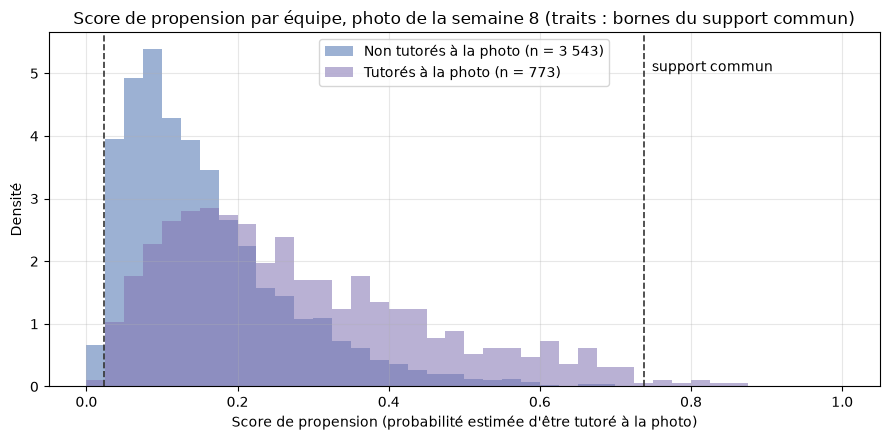

Score des tutorés : de 0,023 à 0,871 ; des non-tutorés : de 0,010 à 0,738. Support commun : [0,023 ; 0,738].
54 étudiants sont hors du support commun (8 tutorés, 46 non tutorés) : pour eux, aucun étudiant de l'autre équipe n'a un score comparable. L'analyse principale les garde ; leur exclusion sera testée en sensibilité (D-56).


In [11]:
score = conception["score"]
traite = conception["traite"]
auc = causal.auc_par_les_rangs(score, traite)
support = conception["support"]
bas, haut = support["bornes"]
print(f"AUC du score : {nombre(auc, 3)}. En prenant au hasard un tutoré et un non-tutoré de la photo, le score place le "
      f"tutoré au-dessus dans {nombre(100 * auc, 0)} % des cas. L'orientation vers le tutorat dépend donc nettement du "
      "profil et de l'activité (d'où la nécessité de rééquilibrer les équipes), sans être parfaitement prévisible : "
      "des profils comparables existent dans les deux équipes.")

figure, axe = plt.subplots(figsize=(9, 4.5))
intervalles = np.linspace(0, 1, 41)
axe.hist(score[traite == 0], bins=intervalles, density=True, alpha=0.55, color="#4C72B0",
         label=f"Non tutorés à la photo (n = {entier((traite == 0).sum())})")
axe.hist(score[traite == 1], bins=intervalles, density=True, alpha=0.55, color="#8172B2",
         label=f"Tutorés à la photo (n = {entier((traite == 1).sum())})")
for borne in (bas, haut):
    axe.axvline(borne, color="#333333", linestyle="--", linewidth=1.2)
axe.text(haut, axe.get_ylim()[1] * 0.92, "  support commun", ha="left", va="top", fontsize=10)
axe.set_xlabel("Score de propension (probabilité estimée d'être tutoré à la photo)")
axe.set_ylabel("Densité")
axe.set_title(f"Score de propension par équipe, photo de la semaine {L} (traits : bornes du support commun)")
axe.legend()
axe.grid(alpha=0.3)
enregistrer(figure, "05_score_propension.png")

t_min, t_max = support["tutores_min_max"]
a_min, a_max = support["autres_min_max"]
hors_t, hors_a = support["hors_support_tutores"], support["hors_support_autres"]
print(f"Score des tutorés : de {nombre(t_min, 3)} à {nombre(t_max, 3)} ; des non-tutorés : de {nombre(a_min, 3)} à "
      f"{nombre(a_max, 3)}. Support commun : [{nombre(bas, 3)} ; {nombre(haut, 3)}].")
print(f"{entier(hors_t + hors_a)} étudiants sont hors du support commun ({entier(hors_t)} tutorés, {entier(hors_a)} non tutorés) : "
      "pour eux, aucun étudiant de l'autre équipe n'a un score comparable. L'analyse principale les garde ; leur exclusion "
      "sera testée en sensibilité (D-56).")

## 6. Les poids et l'équilibre (CA-03)

Chaque étudiant reçoit un **poids stabilisé** (D-56) : un tutoré qui avait peu de chances d'être tutoré compte davantage, un non-tutoré qui ressemblait beaucoup aux tutorés aussi. Après pondération, les deux équipes doivent se ressembler, comme si le tutorat avait été tiré au sort parmi des profils comparables. Les poids extrêmes sont ramenés aux 1er et 99e percentiles (troncature), pour qu'aucun étudiant ne pèse trop lourd.

In [12]:
bruts = conception["poids_bruts"]
poids = conception["poids"]
resume_poids = pd.DataFrame({
    "Moyenne": [bruts.mean(), poids.mean()],
    "Minimum": [bruts.min(), poids.min()],
    "Maximum": [bruts.max(), poids.max()],
}, index=["Avant troncature", "Après troncature"])
display(resume_poids.round(3))
b_bas, b_haut = conception["bornes_troncature"]
tailles = conception["tailles_effectives"]
print(f"Bornes de troncature (percentiles {config.PERCENTILES_TRONCATURE[0]} et {config.PERCENTILES_TRONCATURE[1]}) : "
      f"[{nombre(b_bas, 3)} ; {nombre(b_haut, 3)}] ; {entier(conception['nb_poids_modifies'])} poids modifiés sur "
      f"{entier(len(poids))}.")
print(f"Tailles effectives : {entier(round(tailles['tutores']))} pour {entier((traite == 1).sum())} tutorés, "
      f"{entier(round(tailles['autres']))} pour {entier((traite == 0).sum())} non tutorés. La pondération concentre le poids "
      "sur une partie des tutorés (ceux dont le profil ressemble le plus aux non-tutorés) : l'équipe des tutorés compte "
      "comme environ " + entier(round(tailles["tutores"])) + " étudiants, ce qui élargira un peu les intervalles de confiance.")

,Moyenne,Minimum,Maximum
Avant troncature,1.004,0.206,7.763
Après troncature,0.992,0.289,2.794


Bornes de troncature (percentiles 1 et 99) : [0,289 ; 2,794] ; 88 poids modifiés sur 4 316.
Tailles effectives : 518 pour 773 tutorés, 3 431 pour 3 543 non tutorés. La pondération concentre le poids sur une partie des tutorés (ceux dont le profil ressemble le plus aux non-tutorés) : l'équipe des tutorés compte comme environ 518 étudiants, ce qui élargira un peu les intervalles de confiance.


In [13]:
equilibre = conception["equilibre"]
tableau_equilibre = pd.DataFrame({
    "SMD avant": equilibre["smd_avant"].to_numpy(),
    "SMD après": equilibre["smd_apres"].to_numpy(),
    f"|SMD| < {nombre(config.SEUIL_SMD)}": np.where(equilibre["equilibre"], "oui", "non"),
}, index=[libelle(c, avec_reference=False) for c in equilibre["variable"]])
display(tableau_equilibre.round(3))

,SMD avant,SMD après,"|SMD| < 0,1"
Âge,0.162,0.020,oui
Note du bac,-0.349,0.002,oui
Distance au campus,0.139,0.060,oui
"Connexions LMS, moyenne sem. 1-8",-0.598,-0.036,oui
"Devoirs rendus, moyenne sem. 1-8",-0.495,-0.029,oui
"Note moyenne, sem. 1-8",-0.757,-0.048,oui
"Absences, moyenne sem. 1-8",0.665,0.046,oui
Cohorte : 2024,-0.039,-0.003,oui
Cohorte : 2025,0.039,0.003,oui
Genre : F,-0.092,-0.004,oui


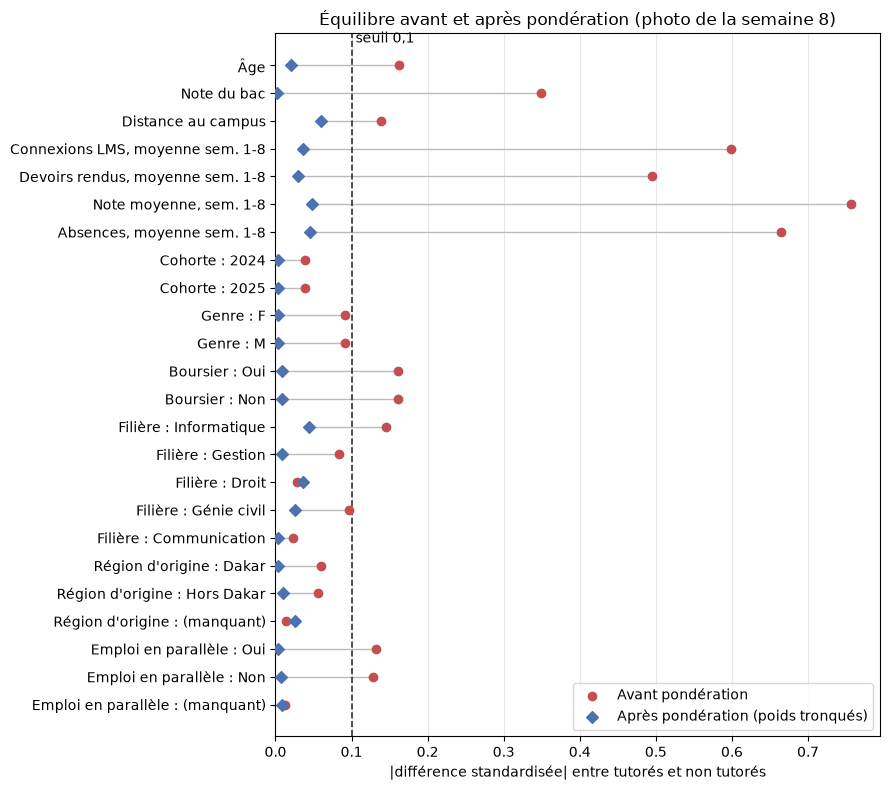

In [14]:
ordre = equilibre.iloc[::-1]
etiquettes = [libelle(c, avec_reference=False) for c in ordre["variable"]]
positions = np.arange(len(ordre))
figure, axe = plt.subplots(figsize=(9, 8))
axe.scatter(ordre["smd_avant"].abs(), positions, color="#C44E52", label="Avant pondération", zorder=3)
axe.scatter(ordre["smd_apres"].abs(), positions, color="#4C72B0", marker="D", label="Après pondération (poids tronqués)",
            zorder=3)
for position, avant, apres in zip(positions, ordre["smd_avant"].abs(), ordre["smd_apres"].abs()):
    axe.plot([avant, apres], [position, position], color="#BBBBBB", linewidth=1, zorder=2)
axe.axvline(config.SEUIL_SMD, color="#333333", linestyle="--", linewidth=1.2)
axe.text(config.SEUIL_SMD, len(ordre) - 0.3, f" seuil {nombre(config.SEUIL_SMD)}", fontsize=10, va="bottom")
axe.set_yticks(positions)
axe.set_yticklabels(etiquettes, fontsize=10)
axe.set_xlim(left=0)
axe.set_xlabel("|différence standardisée| entre tutorés et non tutorés")
axe.set_title(f"Équilibre avant et après pondération (photo de la semaine {L})")
axe.legend(loc="lower right")
axe.grid(axis="x", alpha=0.3)
enregistrer(figure, "05_love_plot.png")

In [15]:
avant = equilibre.loc[equilibre["smd_avant"].abs().idxmax()]
apres = equilibre.loc[equilibre["smd_apres"].abs().idxmax()]
non_equilibrees = equilibre[~equilibre["equilibre"]]
print(f"Avant pondération, le plus grand écart est de {nombre(abs(avant['smd_avant']), 3)} "
      f"({libelle(avant['variable'], avec_reference=False)}) : les deux équipes sont très différentes, surtout sur l'activité "
      "des premières semaines.")
print(f"Après pondération, le plus grand écart est de {nombre(abs(apres['smd_apres']), 3)} "
      f"({libelle(apres['variable'], avec_reference=False)}), sur {len(equilibre)} lignes vérifiées.")
if conception["critere_atteint"]:
    print(f"Critère atteint : toutes les lignes ont |SMD| < {nombre(config.SEUIL_SMD)} après pondération. "
          + ("La retouche fixée d'avance (carrés des variables numériques) a été nécessaire." if conception["retouche"]
             else "La retouche prévue (carrés des variables numériques) n'a pas été nécessaire."))
    print("Sur les variables mesurées, les deux équipes pondérées se ressemblent : la comparaison de CA-04 pourra se faire "
          "à profil et activité comparables. Cela ne dit rien des facteurs non mesurés (motivation…), évalués par l'E-value.")
else:
    print(f"Critère NON atteint : {len(non_equilibrees)} ligne(s) restent à |SMD| ≥ {nombre(config.SEUIL_SMD)} après "
          + ("la retouche fixée d'avance" if conception["retouche"] else "pondération")
          + " : " + ", ".join(libelle(c, avec_reference=False) for c in non_equilibrees["variable"]) + ". Résultat rapporté tel quel.")

Avant pondération, le plus grand écart est de 0,757 (Note moyenne, sem. 1-8) : les deux équipes sont très différentes, surtout sur l'activité des premières semaines.
Après pondération, le plus grand écart est de 0,060 (Distance au campus), sur 24 lignes vérifiées.
Critère atteint : toutes les lignes ont |SMD| < 0,1 après pondération. La retouche prévue (carrés des variables numériques) n'a pas été nécessaire.
Sur les variables mesurées, les deux équipes pondérées se ressemblent : la comparaison de CA-04 pourra se faire à profil et activité comparables. Cela ne dit rien des facteurs non mesurés (motivation…), évalués par l'E-value.


## 7. Diagnostic hors critère

La relecture RV02 (RV02-06) a vérifié l'équilibre de variables mesurées **avant la photo** mais **absentes du score** : notes et connexions des deux dernières semaines, mention du bac, région détaillée, nombre de semaines inactives. Ce tableau est un **diagnostic** : il ne compte pas dans le critère, et le score n'est **pas** modifié au vu de ces chiffres (D-61, point 8).

In [16]:
diagnostic = causal.diagnostic_hors_critere(population, periode, conception["traite"], conception["poids"], L)
NOMS_DIAGNOSTIC = {"mention_bac": "Mention du bac", "region_origine": "Région d'origine"}


def libelle_diagnostic(variable):
    """Texte lisible d'une ligne du diagnostic."""
    if config.SEPARATEUR_INDICATRICE in variable:
        nom, modalite = variable.split(config.SEPARATEUR_INDICATRICE)
        return f"{NOMS_DIAGNOSTIC[nom]} : {modalite}"
    if variable.startswith("note_moyenne"):
        return "Note moyenne, " + variable.split(" ", 1)[1]
    if variable.startswith("nb_connexions_lms"):
        return "Connexions LMS, " + variable.split(" ", 1)[1]
    return variable.capitalize()


tableau_diagnostic = pd.DataFrame({"SMD avant": diagnostic["smd_avant"].to_numpy(),
                                   "SMD après": diagnostic["smd_apres"].to_numpy()},
                                  index=[libelle_diagnostic(v) for v in diagnostic["variable"]])
display(tableau_diagnostic.round(3))
proches = diagnostic[diagnostic["smd_apres"].abs() >= 0.09].sort_values("smd_apres", key=abs, ascending=False)
depassent = int((diagnostic["smd_apres"].abs() >= config.SEUIL_SMD).sum())
debuts_tot = int((population.loc[population["tutore_photo"] == 1, "semaine_debut_tutorat"]
                  <= L - config.SEMAINES_RECENTES_DIAGNOSTIC).sum())
print(f"Après pondération, {depassent} de ces {len(diagnostic)} lignes atteint le seuil de {nombre(config.SEUIL_SMD)} ; "
      f"{len(proches)} s'en approchent (|SMD| ≥ 0,09) : "
      + " ; ".join(f"{libelle_diagnostic(v)} {nombre(x, 4)}" for v, x in zip(proches["variable"], proches["smd_apres"]))
      + ". Le critère est donc atteint, mais de justesse sur des variables liées au décrochage.")
print("Lecture : la mention découle de la note du bac (D-10) ; son écart montre que la pondération équilibre la moyenne "
      "de la note, pas toute sa distribution. Pour les notes et connexions des dernières semaines, "
      f"{entier(debuts_tot)} des {entier(tutores_photo)} tutorés avaient déjà commencé le tutorat au plus tard en semaine "
      f"{L - config.SEMAINES_RECENTES_DIAGNOSTIC} : leur écart peut venir de l'effet du tutorat lui-même (médiateur) ; "
      "c'est pourquoi ces semaines ne sont pas ajoutées au score.")

,SMD avant,SMD après
"Note moyenne, semaines 7-8",-0.382,0.100
"Connexions LMS, semaines 7-8",-0.494,-0.092
Mention du bac : Passable,0.388,0.097
Mention du bac : Assez bien,-0.137,-0.094
Mention du bac : Bien,-0.263,-0.071
Mention du bac : Très bien,-0.138,0.086
Région d'origine : Dakar,-0.060,0.003
Région d'origine : Diourbel,0.005,-0.037
Région d'origine : Fatick,0.051,-0.003
Région d'origine : Kaffrine,0.022,0.024


Après pondération, 0 de ces 22 lignes atteint le seuil de 0,1 ; 4 s'en approchent (|SMD| ≥ 0,09) : Note moyenne, semaines 7-8 0,0997 ; Mention du bac : Passable 0,0974 ; Mention du bac : Assez bien -0,0943 ; Connexions LMS, semaines 7-8 -0,0924. Le critère est donc atteint, mais de justesse sur des variables liées au décrochage.
Lecture : la mention découle de la note du bac (D-10) ; son écart montre que la pondération équilibre la moyenne de la note, pas toute sa distribution. Pour les notes et connexions des dernières semaines, 540 des 773 tutorés avaient déjà commencé le tutorat au plus tard en semaine 6 : leur écart peut venir de l'effet du tutorat lui-même (médiateur) ; c'est pourquoi ces semaines ne sont pas ajoutées au score.


## 8. Ce qu'on estime exactement

**La question précise** (D-61, point 11) : on estime *l'effet d'avoir commencé le tutorat au plus tard en semaine 8, chez les étudiants encore présents à la fin de la semaine 8, sur le décrochage des semaines 9 à 30*.

**Trois conditions** pour lire le résultat comme un effet (D-59) :
1. **pas de facteur caché important** : aucune variable non mesurée (motivation, famille, santé…) ne pousse à la fois vers le tutorat et vers le décrochage au-delà de ce que le profil et l'activité captent ;
2. **chaque profil pouvait être tutoré ou non** : pour tout type d'étudiant de la photo, on trouve des tutorés et des non-tutorés (support commun, section 5) ;
3. **un score bien construit** : après pondération, les deux équipes se ressemblent sur les variables mesurées (section 6).

**Biais écrits d'avance**, avant de regarder le résultat (D-59, D-61) :

In [17]:
futurs = photos.set_index("photo").loc[L, "pct_futurs_tutores"]
demandes = entree["motifs"].get("demande personnelle", 0)
silencieux = estime["silencieux_par_semaine"]
print(f"- Vers « aucun effet » (estimation prudente) : {nombre(futurs)} % des non-tutorés de la photo commenceront le "
      f"tutorat plus tard (dilution) ; chez les tutorés, en moyenne {nombre(estime['recouvrement_moyen'])} des {L} semaines "
      "de la fenêtre d'activité vont de la semaine du début à la photo (une partie de l'effet peut être absorbée par l'ajustement) ; "
      "le HR est une moyenne sur toute la population et toute la période.")
print(f"- En sens inverse (effet surestimé) : la motivation n'est pas mesurée ; {entier(demandes)} tutorats viennent d'une "
      "demande personnelle, et des étudiants motivés peuvent à la fois demander le tutorat et moins décrocher.")
print(f"- La photo s'appuie sur jusqu'à {config.SEUIL_INACTIVITE - 1} semaines postérieures : {entier(estime['nb_silencieux'])} "
      "décrochages silencieux (toutes équipes) commencés en semaine "
      + ", ".join(f"{int(semaine)} ({entier(n)})" for semaine, n in silencieux.items())
      + f" ne sont exclus de la photo que grâce aux semaines suivantes ; inversement, {entier(estime['inactifs_semaine_photo'])} "
      f"étudiants de la photo étaient inactifs en semaine {L} (dont {entier(estime['inactifs_depuis_semaine_precedente'])} "
      f"depuis la semaine {L - 1}). Si le tutorat aide à reprendre, il influence un peu qui figure sur la photo ; les effectifs "
      "sont petits.")
print(f"- L'effet du tutorat pendant les semaines 1 à {L} n'est pas mesuré : {entier(estime['tutores_partis_avant'])} "
      "tutorés sont partis avant la photo.")

- Vers « aucun effet » (estimation prudente) : 11,0 % des non-tutorés de la photo commenceront le tutorat plus tard (dilution) ; chez les tutorés, en moyenne 3,6 des 8 semaines de la fenêtre d'activité vont de la semaine du début à la photo (une partie de l'effet peut être absorbée par l'ajustement) ; le HR est une moyenne sur toute la population et toute la période.
- En sens inverse (effet surestimé) : la motivation n'est pas mesurée ; 203 tutorats viennent d'une demande personnelle, et des étudiants motivés peuvent à la fois demander le tutorat et moins décrocher.
- La photo s'appuie sur jusqu'à 3 semaines postérieures : 83 décrochages silencieux (toutes équipes) commencés en semaine 6 (34), 7 (26), 8 (23) ne sont exclus de la photo que grâce aux semaines suivantes ; inversement, 15 étudiants de la photo étaient inactifs en semaine 8 (dont 3 depuis la semaine 7). Si le tutorat aide à reprendre, il influence un peu qui figure sur la photo ; les effectifs sont petits.
- L'effet du tut

## 9. L'effet du tutorat (CA-04)

La conception (sections 1 à 8) a été relue (R02) puis figée (D-61). Les résultats ci-dessous sont lus dans `data/processed/resultats/` (produits par `python run_all.py`). Sur la photo de la semaine 8, chaque étudiant reçoit son poids (section 6) ; on suit les deux équipes pondérées de la semaine 9 à la semaine 30 (22 semaines). L'incertitude vient d'un **bootstrap** de 500 tirages : toute la chaîne (score, poids, troncature, courbes, mesures) est refaite sur chaque tirage d'étudiants avec remise (D-61).

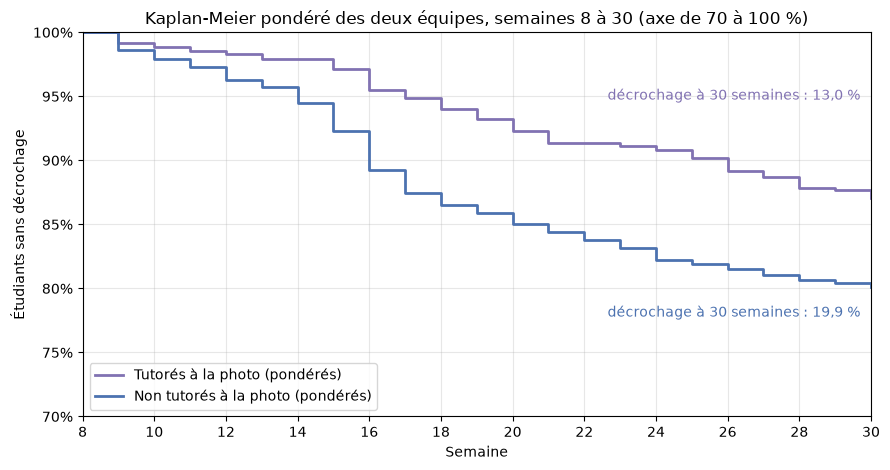

In [18]:
def lire_resultat(nom):
    """Lit un résultat enregistré par run_all.py (data/processed/resultats/)."""
    return pd.read_csv(config.DOSSIER_RESULTATS / nom, sep=config.SEPARATEUR_PROCESSED, encoding=config.ENCODAGE)


courbes = lire_resultat("ca_courbes_ponderees.csv")
effet = lire_resultat("ca_effet_principal.csv").set_index("mesure")
diagnostic_tirages = lire_resultat("ca_diagnostic_bootstrap.csv").set_index("analyse")
schoenfeld = lire_resultat("ca_schoenfeld_principal.csv").iloc[0]
COULEUR_TUTORES, COULEUR_AUTRES = "#8172B2", "#4C72B0"

figure, axe = plt.subplots(figsize=(9, 4.8))
axe.step(courbes["semaine"], courbes["survie_tutores"], where="post", color=COULEUR_TUTORES, linewidth=2,
         label="Tutorés à la photo (pondérés)")
axe.step(courbes["semaine"], courbes["survie_non_tutores"], where="post", color=COULEUR_AUTRES, linewidth=2,
         label="Non tutorés à la photo (pondérés)")
fin = courbes.iloc[-1]
# Étiquettes dans les zones vides : au-dessus de la courbe des tutorés, sous celle des autres.
for colonne, risque, couleur, decalage in [("survie_tutores", "risque_tutores", COULEUR_TUTORES, 0.08),
                                           ("survie_non_tutores", "risque_non_tutores", COULEUR_AUTRES, -0.02)]:
    axe.text(config.N_SEMAINES - 0.3, fin[colonne] + decalage,
             f"décrochage à 30 semaines : {nombre(100 * effet.loc[risque, 'estimation'])} %",
             ha="right", va="center", fontsize=10, color=couleur)
axe.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axe.set_ylim(0.7, 1.0)
axe.set_xlim(L, config.N_SEMAINES)
axe.set_xticks(range(L, config.N_SEMAINES + 1, 2))
axe.set_xlabel("Semaine")
axe.set_ylabel("Étudiants sans décrochage")
axe.set_title(f"Kaplan-Meier pondéré des deux équipes, semaines {L} à {config.N_SEMAINES} (axe de 70 à 100 %)")
axe.legend(loc="lower left")
axe.grid(alpha=0.3)
enregistrer(figure, "05_km_ponderees.png")

In [19]:
LIBELLES_EFFET = {
    "risque_tutores": "Risque de décrochage à 30 semaines, tutorés",
    "risque_non_tutores": "Risque de décrochage à 30 semaines, non tutorés",
    "difference_risque": "Différence de risque (tutorés − non tutorés)",
    "rapport_risques": "Rapport des risques (RR)",
    "rmst_tutores": "Semaines sans décrochage sur 22 (RMST), tutorés",
    "rmst_non_tutores": "Semaines sans décrochage sur 22 (RMST), non tutorés",
    "difference_rmst": "Différence de RMST (semaines)",
    "hr": "Hazard ratio (HR)",
    "hr_ic_sandwich": "HR, IC « sandwich » du modèle (pour information)",
}
tableau_effet = effet.loc[list(LIBELLES_EFFET), ["estimation", "ic_bas", "ic_haut"]]
tableau_effet.index = [LIBELLES_EFFET[m] for m in tableau_effet.index]
display(tableau_effet.rename(columns={"estimation": "Estimation", "ic_bas": "IC 95 % bas",
                                      "ic_haut": "IC 95 % haut"}).round(4))
principal = diagnostic_tirages.loc["analyse principale"]
print(f"Bootstrap : {entier(principal['tirages'])} tirages, {entier(principal['echecs'])} en échec ; dans "
      f"{nombre(100 * principal['part_hors_critere'], 0)} % des tirages, au moins une ligne d'équilibre atteint "
      f"|SMD| ≥ {nombre(config.SEUIL_SMD)} (le critère est tenu sur la photo elle-même, de justesse dans certains tirages).")
p_schoenfeld = schoenfeld["p"]
if p_schoenfeld < config.ALPHA:
    print(f"Test de Schoenfeld sur le Cox pondéré (indicatif) : p = {nombre(p_schoenfeld, 3)} < 0,05. Le rapport des "
          "risques instantanés n'est pas constant au fil des semaines : le HR se lit comme une moyenne sur la période, "
          "et ce sont le risque à 30 semaines et le RMST qui portent la conclusion (D-57).")
else:
    print(f"Test de Schoenfeld sur le Cox pondéré (indicatif) : p = {nombre(p_schoenfeld, 3)}, pas d'écart net à la "
          "proportionnalité.")

,Estimation,IC 95 % bas,IC 95 % haut
"Risque de décrochage à 30 semaines, tutorés",0.1296,0.1060,0.1577
"Risque de décrochage à 30 semaines, non tutorés",0.1990,0.1852,0.2123
Différence de risque (tutorés − non tutorés),-0.0695,-0.0956,-0.0398
Rapport des risques (RR),0.6510,0.5342,0.7969
"Semaines sans décrochage sur 22 (RMST), tutorés",20.6601,20.3352,20.9101
"Semaines sans décrochage sur 22 (RMST), non tutorés",19.4591,19.2746,19.6553
Différence de RMST (semaines),1.2010,0.8203,1.4790
Hazard ratio (HR),0.6129,0.4996,0.7591
"HR, IC « sandwich » du modèle (pour information)",0.6129,0.4906,0.7657


Bootstrap : 500 tirages, 0 en échec ; dans 12 % des tirages, au moins une ligne d'équilibre atteint |SMD| ≥ 0,1 (le critère est tenu sur la photo elle-même, de justesse dans certains tirages).
Test de Schoenfeld sur le Cox pondéré (indicatif) : p = 0,014 < 0,05. Le rapport des risques instantanés n'est pas constant au fil des semaines : le HR se lit comme une moyenne sur la période, et ce sont le risque à 30 semaines et le RMST qui portent la conclusion (D-57).


In [20]:
risque_t, risque_n = effet.loc["risque_tutores"], effet.loc["risque_non_tutores"]
difference, rmst = effet.loc["difference_risque"], effet.loc["difference_rmst"]


def intervalle_texte(ligne, facteur=1, decimales=1):
    return f"IC à 95 % : {nombre(facteur * ligne['ic_bas'], decimales)} à {nombre(facteur * ligne['ic_haut'], decimales)}"


print(f"Parmi les étudiants encore présents à la fin de la semaine {L}, {nombre(100 * risque_t['estimation'])} % des tutorés "
      f"décrochent avant la semaine {config.N_SEMAINES}, contre {nombre(100 * risque_n['estimation'])} % des non-tutorés de "
      f"profil et d'activité comparables : si les trois conditions de la section 8 sont réunies, le tutorat réduit le "
      f"risque de décrochage de {nombre(-100 * difference['estimation'])} points (IC à 95 % : "
      f"{nombre(-100 * difference['ic_haut'])} à {nombre(-100 * difference['ic_bas'])} points).")
print(f"Sur les {config.N_SEMAINES - L} semaines suivantes, un étudiant tutoré reste en moyenne "
      f"{nombre(rmst['estimation'], 1)} semaine(s) de plus sans décrocher ({intervalle_texte(rmst)}). "
      f"En complément, HR = {nombre(effet.loc['hr', 'estimation'], 2)} ({intervalle_texte(effet.loc['hr'], 1, 2)}).")

Parmi les étudiants encore présents à la fin de la semaine 8, 13,0 % des tutorés décrochent avant la semaine 30, contre 19,9 % des non-tutorés de profil et d'activité comparables : si les trois conditions de la section 8 sont réunies, le tutorat réduit le risque de décrochage de 6,9 points (IC à 95 % : 4,0 à 9,6 points).
Sur les 22 semaines suivantes, un étudiant tutoré reste en moyenne 1,2 semaine(s) de plus sans décrocher (IC à 95 % : 0,8 à 1,5). En complément, HR = 0,61 (IC à 95 % : 0,50 à 0,76).


## 10. La sensibilité (CA-05)

Chaque variante refait **toute la chaîne** (photo, score, poids, équilibre, effet, 100 tirages) avec un seul choix modifié (D-58, D-61). Les variantes avaient 200 tirages ; le repli prévu par D-61 a été appliqué le 23/11 (D-67, point 8), car `run_all.py` dépassait 15 min au premier lancement après une installation neuve. Ce repli ne change que la largeur des intervalles des variantes, pas leurs estimations ; l'analyse principale garde ses 500 tirages. Elles sont présentées **à côté** de l'analyse principale, jamais à sa place. Le Cox dépendant du temps (D-62) répond à une question voisine : tous les étudiants dès la semaine 1, à profil et activité passée égaux.

In [21]:
sensibilite = lire_resultat("ca_sensibilite.csv")
cox_temps = lire_resultat("ca_cox_dependant_du_temps.csv").iloc[0]


def avec_ic(ligne, mesure, facteur=1, decimales=3):
    return (f"{nombre(facteur * ligne[mesure], decimales)} [{nombre(facteur * ligne[mesure + '_ic_bas'], decimales)} ; "
            f"{nombre(facteur * ligne[mesure + '_ic_haut'], decimales)}]")


tableau_sensibilite = pd.DataFrame({
    "Étudiants": [entier(n) for n in sensibilite["etudiants"]],
    "Tutorés": [entier(n) for n in sensibilite["tutores"]],
    "|SMD| max": [nombre(x, 3) for x in sensibilite["smd_max"]],
    "Retouche": np.where(sensibilite["retouche"], "oui", "non"),
    "Critère atteint": np.where(sensibilite["critere_atteint"], "oui", "non"),
    "Tirages hors critère": [f"{nombre(100 * x, 0)} %" for x in sensibilite["part_hors_critere"]],
    "Différence de risque (points) [IC]": [avec_ic(l, "difference_risque", 100, 1) for _, l in sensibilite.iterrows()],
    "HR [IC]": [avec_ic(l, "hr") for _, l in sensibilite.iterrows()],
    "Différence de RMST (semaines)": [f"{nombre(l['difference_rmst'], 2)} sur {int(l['horizon_rmst'])}"
                                      for _, l in sensibilite.iterrows()],
}, index=sensibilite["analyse"])
display(tableau_sensibilite)
print("Le RMST n'a pas le même horizon d'une photo à l'autre (30 − L semaines) : sa différence se compare entre analyses "
      "de même photo seulement.")
for _, ligne in sensibilite[~sensibilite["critere_atteint"]].iterrows():
    print(f"Variante « {ligne['analyse']} » : la retouche fixée d'avance a "
          + ("été appliquée" if ligne["retouche"] else "pas été appliquée")
          + f", et le critère d'équilibre n'est pas atteint (|SMD| maximal {nombre(ligne['smd_max'], 3)}) : résultat "
          "rapporté tel quel (D-56, D-61).")

,Étudiants,Tutorés,|SMD| max,Retouche,Critère atteint,Tirages hors critère,Différence de risque (points) [IC],HR [IC],Différence de RMST (semaines)
analyse,,,,,,,,,
analyse principale,4 316,773,"0,060",non,oui,12 %,"-6,9 [-9,6 ; -4,0]","0,613 [0,500 ; 0,759]","1,20 sur 22"
seuil de 3 semaines,4 314,772,"0,061",non,oui,10 %,"-6,7 [-9,3 ; -4,0]","0,623 [0,501 ; 0,757]","1,19 sur 22"
seuil de 5 semaines,4 318,774,"0,060",non,oui,7 %,"-6,9 [-9,8 ; -4,6]","0,615 [0,486 ; 0,725]","1,19 sur 22"
photo en semaine 6,4 473,560,"0,124",oui,non,78 %,"-6,4 [-9,3 ; -2,8]","0,673 [0,539 ; 0,838]","1,21 sur 24"
photo en semaine 10,4 225,971,"0,057",non,oui,0 %,"-5,9 [-8,4 ; -3,3]","0,650 [0,536 ; 0,788]","0,85 sur 20"
fenêtre 1 à 2,4 316,773,"0,066",non,oui,10 %,"-4,7 [-7,2 ; -1,5]","0,727 [0,593 ; 0,895]","0,84 sur 22"
support strict,4 262,765,"0,054",non,oui,4 %,"-7,1 [-9,4 ; -4,2]","0,607 [0,501 ; 0,751]","1,22 sur 22"


Le RMST n'a pas le même horizon d'une photo à l'autre (30 − L semaines) : sa différence se compare entre analyses de même photo seulement.
Variante « photo en semaine 6 » : la retouche fixée d'avance a été appliquée, et le critère d'équilibre n'est pas atteint (|SMD| maximal 0,124) : résultat rapporté tel quel (D-56, D-61).


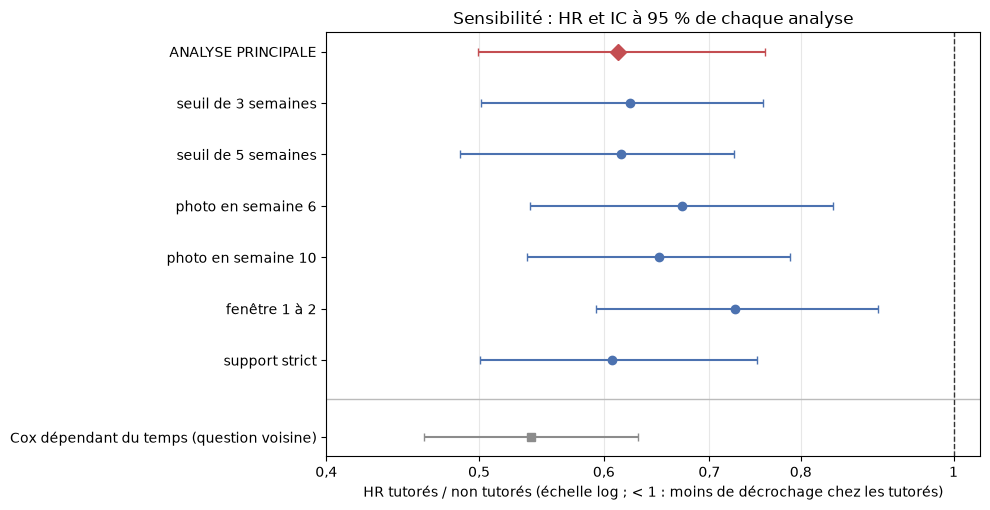

HR des variantes : de 0,61 à 0,73 (analyse principale 0,61) ; Cox dépendant du temps 0,54 [0,46 ; 0,63] sur 4 995 étudiants et 121 811 semaines-étudiants.
Toutes les analyses vont dans le même sens et aucun intervalle ne contient 1 : le sens de la conclusion ne dépend pas des choix de méthode testés ici (l'ampleur varie un peu).


In [22]:
ordre = sensibilite.iloc[::-1].reset_index(drop=True)
figure, axe = plt.subplots(figsize=(10, 5.2))
positions = np.arange(len(ordre)) + 1.5
for position, (_, ligne) in zip(positions, ordre.iterrows()):
    principale = ligne["analyse"] == "analyse principale"
    couleur = "#C44E52" if principale else "#4C72B0"
    axe.errorbar(ligne["hr"], position, xerr=[[ligne["hr"] - ligne["hr_ic_bas"]], [ligne["hr_ic_haut"] - ligne["hr"]]],
                 fmt="D" if principale else "o", color=couleur, ecolor=couleur, capsize=3,
                 markersize=8 if principale else 6)
axe.errorbar(cox_temps["hr"], 0, xerr=[[cox_temps["hr"] - cox_temps["ic_bas"]], [cox_temps["ic_haut"] - cox_temps["hr"]]],
             fmt="s", color="#8C8C8C", ecolor="#8C8C8C", capsize=3)
axe.axhline(0.75, color="#BBBBBB", linewidth=1)
etiquettes = ["Cox dépendant du temps (question voisine)"] + [
    a if a != "analyse principale" else "ANALYSE PRINCIPALE" for a in ordre["analyse"]]
axe.set_yticks([0] + list(positions))
axe.set_yticklabels(etiquettes, fontsize=10)
axe.axvline(1, color="#333333", linestyle="--", linewidth=1)
axe.set_xscale("log")
axe.set_xticks([0.4, 0.5, 0.6, 0.7, 0.8, 1.0])
axe.set_xticklabels(["0,4", "0,5", "0,6", "0,7", "0,8", "1"])
axe.minorticks_off()
axe.set_xlabel("HR tutorés / non tutorés (échelle log ; < 1 : moins de décrochage chez les tutorés)")
axe.set_title("Sensibilité : HR et IC à 95 % de chaque analyse")
axe.grid(axis="x", alpha=0.3)
enregistrer(figure, "05_sensibilite.png")

variantes_seules = sensibilite[sensibilite["analyse"] != "analyse principale"]
toutes_sous_1 = (sensibilite["hr_ic_haut"] < 1).all() and cox_temps["ic_haut"] < 1
print(f"HR des variantes : de {nombre(variantes_seules['hr'].min(), 2)} à {nombre(variantes_seules['hr'].max(), 2)} "
      f"(analyse principale {nombre(sensibilite.iloc[0]['hr'], 2)}) ; Cox dépendant du temps "
      f"{nombre(cox_temps['hr'], 2)} [{nombre(cox_temps['ic_bas'], 2)} ; {nombre(cox_temps['ic_haut'], 2)}] sur "
      f"{entier(cox_temps['etudiants'])} étudiants et {entier(cox_temps['semaines_etudiants'])} semaines-étudiants.")
print("Toutes les analyses vont dans le même sens et aucun intervalle ne contient 1 : le sens de la conclusion ne dépend "
      "pas des choix de méthode testés ici (l'ampleur varie un peu)." if toutes_sous_1 else
      "Au moins une analyse a un intervalle qui contient 1 : la conclusion dépend en partie des choix de méthode.")

In [23]:
rr = effet.loc["rapport_risques"]
valeur_e, borne_e = effet.loc["e_value", "estimation"], effet.loc["e_value_borne_ic", "estimation"]
hr_emploi = lire_resultat("ml_hr_cox_2024.csv").set_index("variable").loc["emploi_parallele=Oui", "HR"]
print(f"E-value : {nombre(valeur_e, 2)} pour le RR de {nombre(rr['estimation'], 3)} ; {nombre(borne_e, 2)} pour la borne de "
      f"l'IC la plus proche de 1 ({nombre(rr['ic_haut'], 3)}).")
print(f"Lecture : pour expliquer à lui seul toute l'association observée, un facteur caché (motivation, famille, santé…) "
      f"devrait multiplier par au moins {nombre(valeur_e, 2)} à la fois les chances d'être tutoré et le risque de "
      f"décrocher, au-delà de tout ce que le score prend déjà en compte ; pour rendre l'effet compatible avec « aucun "
      f"effet », il suffirait d'un facteur de {nombre(borne_e, 2)}. À titre de repère, l'emploi en parallèle, la "
      f"variable la plus fortement associée au décrochage dans le Cox de 2024 (notebook 04), a un HR de "
      f"{nombre(hr_emploi, 2)}.")

E-value : 2,44 pour le RR de 0,651 ; 1,82 pour la borne de l'IC la plus proche de 1 (0,797).
Lecture : pour expliquer à lui seul toute l'association observée, un facteur caché (motivation, famille, santé…) devrait multiplier par au moins 2,44 à la fois les chances d'être tutoré et le risque de décrocher, au-delà de tout ce que le score prend déjà en compte ; pour rendre l'effet compatible avec « aucun effet », il suffirait d'un facteur de 1,82. À titre de repère, l'emploi en parallèle, la variable la plus fortement associée au décrochage dans le Cox de 2024 (notebook 04), a un HR de 1,72.


In [24]:
equilibres_courte = lire_resultat("ca_equilibre_fenetre_1_2.csv")
matrices = list(equilibres_courte["matrice"].unique())
comparaison = equilibres_courte.pivot(index="variable", columns="matrice", values="smd_apres")
comparaison = comparaison.reindex([v for v in equilibres_courte["variable"].drop_duplicates()
                                   if v in comparaison.index])
comparaison.index = [libelle(v, avec_reference=False) for v in comparaison.index]
display(comparaison[matrices].rename(columns={m: f"SMD après pondération, {m}" for m in matrices}).round(3))
propre = equilibres_courte[equilibres_courte["matrice"] == matrices[0]]
longue = equilibres_courte[equilibres_courte["matrice"] == matrices[1]]
pire = longue.loc[longue["smd_apres"].abs().idxmax()]
print(f"Avec la {matrices[0]}, les poids équilibrent leurs propres variables (|SMD| maximal "
      f"{nombre(propre['smd_apres'].abs().max(), 3)}), mais sur l'activité de la {matrices[1]} il reste un écart allant "
      f"jusqu'à {nombre(abs(pire['smd_apres']), 3)} ({libelle(pire['variable'], avec_reference=False)}). Cette variante ne "
      "tient pas compte de la mauvaise passe qui précède le tutorat : les tutorés y restent en moins bonne posture, ce "
      "qui tire son estimation vers « aucun effet » ; elle protège en revanche contre l'absorption d'une partie de "
      "l'effet par l'ajustement (D-55).")

matrice,"SMD après pondération, fenêtre 1 à 2","SMD après pondération, fenêtre 1 à 8"
Âge,0.036,0.036
Note du bac,-0.028,-0.028
Distance au campus,0.052,0.052
"Connexions LMS, moyenne sem. 1-8",-0.040,-0.221
"Devoirs rendus, moyenne sem. 1-8",-0.023,-0.152
"Note moyenne, sem. 1-8",-0.066,-0.333
"Absences, moyenne sem. 1-8",0.028,0.266
Cohorte : 2024,-0.025,-0.025
Cohorte : 2025,0.025,0.025
Genre : F,-0.011,-0.011


Avec la fenêtre 1 à 2, les poids équilibrent leurs propres variables (|SMD| maximal 0,066), mais sur l'activité de la fenêtre 1 à 8 il reste un écart allant jusqu'à 0,333 (Note moyenne, sem. 1-8). Cette variante ne tient pas compte de la mauvaise passe qui précède le tutorat : les tutorés y restent en moins bonne posture, ce qui tire son estimation vers « aucun effet » ; elle protège en revanche contre l'absorption d'une partie de l'effet par l'ajustement (D-55).


## 11. Conclusion prudente

In [25]:
variantes_diff = variantes_seules["difference_risque"]
print(f"Ce qui est estimé : l'effet d'avoir commencé le tutorat au plus tard en semaine {L}, chez les étudiants encore "
      f"présents à la fin de la semaine {L}, sur le décrochage des semaines {L + 1} à {config.N_SEMAINES} (D-61).")
print(f"Résultat : risque de décrochage à 30 semaines de {nombre(100 * risque_t['estimation'])} % chez les tutorés contre "
      f"{nombre(100 * risque_n['estimation'])} % chez les non-tutorés comparables, soit une réduction de "
      f"{nombre(-100 * difference['estimation'])} points (IC à 95 % : {nombre(-100 * difference['ic_haut'])} à "
      f"{nombre(-100 * difference['ic_bas'])}) et {nombre(rmst['estimation'], 1)} semaine(s) de plus sans décrochage sur "
      f"{config.N_SEMAINES - L} (IC : {nombre(rmst['ic_bas'], 1)} à {nombre(rmst['ic_haut'], 1)}).")
print(f"Les {len(variantes_seules)} variantes donnent une réduction de {nombre(-100 * variantes_diff.max())} à "
      f"{nombre(-100 * variantes_diff.min())} points ; le Cox dépendant du temps (question voisine) va dans le même sens "
      f"(HR {nombre(cox_temps['hr'], 2)}).")

Ce qui est estimé : l'effet d'avoir commencé le tutorat au plus tard en semaine 8, chez les étudiants encore présents à la fin de la semaine 8, sur le décrochage des semaines 9 à 30 (D-61).
Résultat : risque de décrochage à 30 semaines de 13,0 % chez les tutorés contre 19,9 % chez les non-tutorés comparables, soit une réduction de 6,9 points (IC à 95 % : 4,0 à 9,6) et 1,2 semaine(s) de plus sans décrochage sur 22 (IC : 0,8 à 1,5).
Les 6 variantes donnent une réduction de 4,7 à 7,1 points ; le Cox dépendant du temps (question voisine) va dans le même sens (HR 0,54).


**Ce résultat est un effet seulement si les trois conditions sont réunies** (D-59) : pas de facteur caché important (l'E-value dit quelle force il lui faudrait), chaque profil pouvait être tutoré ou non (support commun), et le score est bien construit (équilibre atteint, de justesse sur quelques variables hors critère, section 7).

**Limites** :
- l'effet du tutorat pendant les semaines 1 à 8 n'est pas mesuré (tutorés partis avant la photo) ;
- les biais écrits d'avance (section 8) tirent l'estimation vers « aucun effet » (dilution par les futurs tutorés, fenêtre d'activité qui recouvre le début du tutorat), sauf la motivation non mesurée, qui joue en sens inverse ;
- le test de Schoenfeld indique que le HR varie au fil des semaines : la conclusion repose sur le risque à 30 semaines et le RMST ;
- les données sont synthétiques : l'estimation sera comparée au vrai effet connu de l'enseignant.